In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_auc_score
)

In [2]:
X, y = make_classification(
    n_samples=10000,
    n_features=10,
    n_informative=5,
    n_redundant=2,
    n_clusters_per_class=1,
    weights=[0.95, 0.05],
    random_state=42
)

print("Dataset shape:", X.shape)

print("\nClass distribution:")
print(pd.Series(y).value_counts())

print("\nClass percentage:")
print(pd.Series(y).value_counts(normalize=True) * 100)

Dataset shape: (10000, 10)

Class distribution:
0    9455
1     545
Name: count, dtype: int64

Class percentage:
0    94.55
1     5.45
Name: proportion, dtype: float64


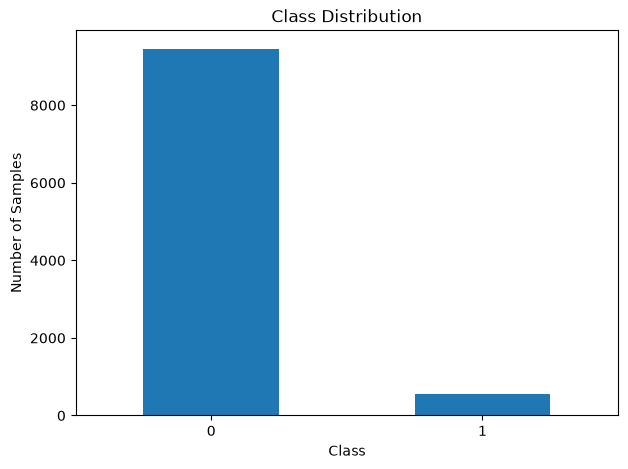

In [3]:
pd.Series(y).value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Class Distribution")
plt.xticks(rotation=0)
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [6]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9915
Precision: 1.0
Recall: 0.8440366972477065
F1: 0.9154228855721394

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1891
           1       1.00      0.84      0.92       109

    accuracy                           0.99      2000
   macro avg       1.00      0.92      0.96      2000
weighted avg       0.99      0.99      0.99      2000



[[1891    0]
 [  17   92]]


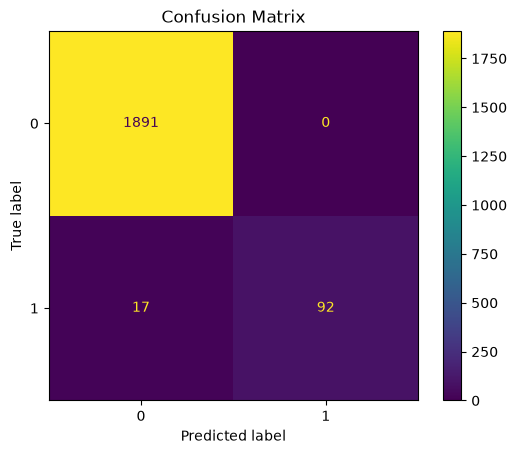

In [7]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm
).plot()

plt.title("Confusion Matrix")
plt.show()

In [8]:
# balanced model

balanced_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    ))
])

balanced_model.fit(X_train, y_train)

balanced_pred = balanced_model.predict(X_test)

In [9]:
print("Balanced Model")

print("Accuracy:",
      accuracy_score(y_test, balanced_pred))

print("Precision:",
      precision_score(y_test, balanced_pred))

print("Recall:",
      recall_score(y_test, balanced_pred))

print("F1:",
      f1_score(y_test, balanced_pred))

Balanced Model
Accuracy: 0.9805
Precision: 0.7611940298507462
Recall: 0.9357798165137615
F1: 0.8395061728395061


## Decision threshold

Normally:
Probability >= 0.50 → Class 1
Probability < 0.50  → Class 0

But 0.50 is not a universal rule.

You can change the threshold depending on the problem.

For example:
Threshold = 0.50
Threshold = 0.30
Threshold = 0.20

A lower threshold generally makes the model more willing to predict the positive class.

In [10]:
probabilities = model.predict_proba(X_test)[:, 1]

In [11]:
threshold_50 = 0.50

pred_50 = (probabilities >= threshold_50).astype(int)

print("Precision:",
      precision_score(y_test, pred_50))

print("Recall:",
      recall_score(y_test, pred_50))

print("F1:",
      f1_score(y_test, pred_50))

Precision: 1.0
Recall: 0.8440366972477065
F1: 0.9154228855721394


In [12]:
threshold_30 = 0.30

pred_30 = (probabilities >= threshold_30).astype(int)

print("Precision:",
      precision_score(y_test, pred_30))

print("Recall:",
      recall_score(y_test, pred_30))

print("F1:",
      f1_score(y_test, pred_30))

Precision: 0.9897959183673469
Recall: 0.8899082568807339
F1: 0.9371980676328503


In [13]:
thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds:

    predictions = (
        probabilities >= threshold
    ).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(results)

print(threshold_df.round(3))

    Threshold  Precision  Recall     F1
0        0.10      0.810   0.936  0.868
1        0.15      0.926   0.917  0.922
2        0.20      0.970   0.899  0.933
3        0.25      0.990   0.899  0.942
4        0.30      0.990   0.890  0.937
5        0.35      0.990   0.881  0.932
6        0.40      1.000   0.881  0.937
7        0.45      1.000   0.872  0.931
8        0.50      1.000   0.844  0.915
9        0.55      1.000   0.844  0.915
10       0.60      1.000   0.844  0.915
11       0.65      1.000   0.844  0.915
12       0.70      1.000   0.844  0.915
13       0.75      1.000   0.835  0.910
14       0.80      1.000   0.817  0.899
15       0.85      1.000   0.789  0.882
16       0.90      1.000   0.771  0.870


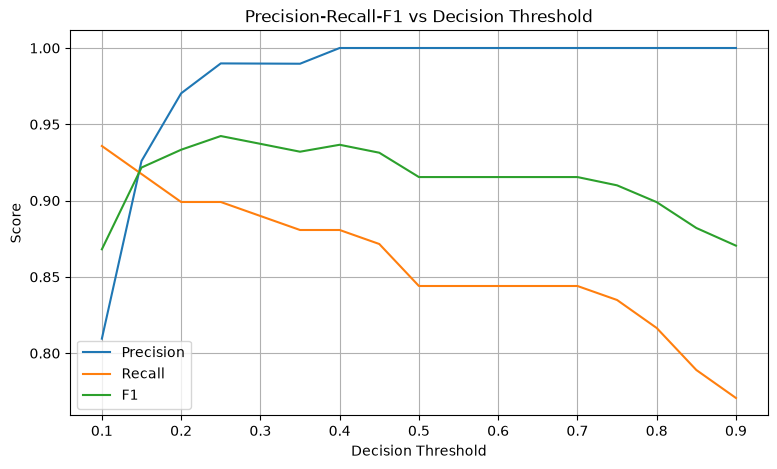

In [14]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1"

)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall-F1 vs Decision Threshold")
plt.legend()
plt.grid()

plt.show()

Generally:

Lower threshold → more positives → higher recall, potentially lower precision

Higher threshold → fewer positives → potentially higher precision, lower recall

In [15]:
best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print(best_row)

Threshold    0.250000
Precision    0.989899
Recall       0.899083
F1           0.942308
Name: 3, dtype: float64


In [16]:
best_threshold = best_row["Threshold"]

print("Best threshold:", best_threshold)
print("Best F1:", best_row["F1"])

Best threshold: 0.25000000000000006
Best F1: 0.9423076923076923


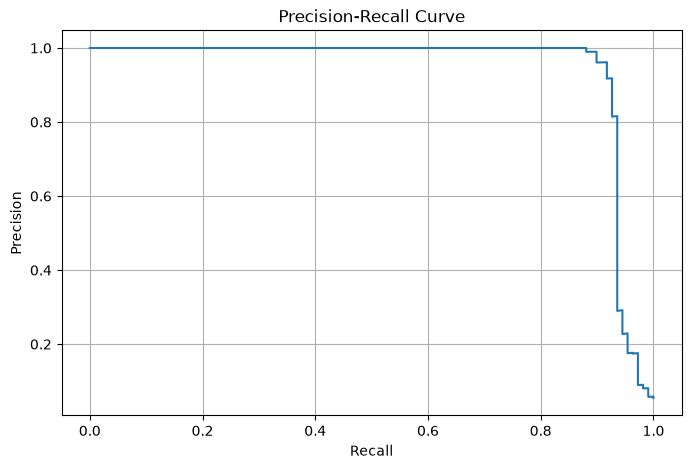

In [17]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    probabilities
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid()

plt.show()